# 06 — Correlação dos dados numéricos originais com `target_dias_atraso`

Este notebook faz uma análise simples e clássica de correlação.

A lógica é:

- carregar o dataset enriquecido;
- manter apenas colunas numéricas;
- retirar automaticamente colunas de texto, datas e objetos;
- calcular correlação de **Pearson** e **Spearman** com `target_dias_atraso`;
- ordenar as variáveis pela força da correlação;
- mostrar gráficos clássicos:
  - barras de correlação;
  - matriz/heatmap de correlação;
  - dispersão das variáveis mais relacionadas com o target;
- destacar correlações muito altas que merecem investigação.

> Importante: correlação não implica causalidade. Uma correlação alta também pode indicar redundância ou leakage.

In [16]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 180)

TARGET = "target_dias_atraso"

# Caminhos mais comuns usados nos notebooks anteriores.
CANDIDATE_PATHS = [
    Path("C:\\Users\\Gabriel\\OneDrive\\Documentos\\projeto_previsao_termino_obras\\data\\processed\\dataset_modelagem_obras_snapshots_enriquecido.csv"),
    Path("/mnt/data/modelagem_outputs/processed/dataset_modelagem_obras_snapshots_enriquecido.csv"),
    Path("/mnt/data/dataset_modelagem_obras_snapshots_enriquecido.csv"),
    Path("modelagem_outputs/processed/dataset_modelagem_obras_snapshots_enriquecido.csv"),
    Path("dataset_modelagem_obras_snapshots_enriquecido.csv"),
]

DATASET_PATH = next(
    (p for p in CANDIDATE_PATHS if p.exists()),
    None
)

if DATASET_PATH is None:
    raise FileNotFoundError(
        "Dataset não encontrado. Ajuste DATASET_PATH para o arquivo "
        "dataset_modelagem_obras_snapshots_enriquecido.csv."
    )

print("Dataset:", DATASET_PATH)

Dataset: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\data\processed\dataset_modelagem_obras_snapshots_enriquecido.csv


In [17]:
# Carrega os dados originais.
df = pd.read_csv(
    DATASET_PATH,
    low_memory=False,
    encoding="utf-8-sig",
)

print("Shape:", df.shape)
print("Quantidade de colunas:", len(df.columns))
print("Quantidade de contratos:", df["id_contrato"].nunique() if "id_contrato" in df.columns else "N/A")

assert TARGET in df.columns, f"A coluna {TARGET} não foi encontrada."

Shape: (633, 109)
Quantidade de colunas: 109
Quantidade de contratos: 48


## 1. Seleção automática das colunas numéricas

Aqui não fazemos seleção manual de features.

O notebook simplesmente mantém colunas numéricas e descarta texto/objetos. Isso permite observar a correlação do target com os valores originais disponíveis no dataset.

In [18]:
# Mantém somente colunas numéricas.
numeric_df = df.select_dtypes(include=[np.number]).copy()

# Remove linhas sem target.
numeric_df = numeric_df[
    numeric_df[TARGET].notna()
].copy()

print("Colunas numéricas encontradas:", len(numeric_df.columns))
print("Linhas utilizadas:", len(numeric_df))

display(
    pd.DataFrame({
        "coluna": numeric_df.columns,
        "tipo": [numeric_df[c].dtype for c in numeric_df.columns],
        "pct_nulos": [numeric_df[c].isna().mean() for c in numeric_df.columns],
        "valores_unicos": [numeric_df[c].nunique(dropna=True) for c in numeric_df.columns],
    })
)

Colunas numéricas encontradas: 96
Linhas utilizadas: 633


,coluna,tipo,pct_nulos,valores_unicos
0,id_contrato,int64,0.000000,48
1,id_setor_divisao,int64,0.000000,4
2,ano_contrato,int64,0.000000,8
3,prazo_original_dias,int64,0.000000,15
4,valor_total_contrato,float64,0.000000,48
5,log_valor_total_contrato,float64,0.000000,48
6,flag_valor_licitado_informado,int64,0.000000,2
7,valor_licitado_modelo,float64,0.492891,20
8,log_valor_licitado,float64,0.492891,20
9,perc_desconto_modelo,float64,0.492891,19


## 2. Correlação de Pearson e Spearman com o target

- **Pearson** mede principalmente relação linear.
- **Spearman** mede relação monotônica e costuma ser mais robusto quando a relação não é perfeitamente linear.

As duas medidas são úteis e devem ser vistas em conjunto.

In [19]:
features_numericas = [
    c for c in numeric_df.columns
    if c != TARGET
]

rows = []

for coluna in features_numericas:
    temp = numeric_df[
        [coluna, TARGET]
    ].dropna()

    # Ignora variáveis constantes ou praticamente sem dados.
    if len(temp) < 3 or temp[coluna].nunique() <= 1:
        continue

    pearson = temp[coluna].corr(
        temp[TARGET],
        method="pearson",
    )

    spearman = temp[coluna].corr(
        temp[TARGET],
        method="spearman",
    )

    rows.append({
        "variavel": coluna,
        "pearson": pearson,
        "abs_pearson": abs(pearson),
        "spearman": spearman,
        "abs_spearman": abs(spearman),
        "n": len(temp),
        "pct_nulos": numeric_df[coluna].isna().mean(),
        "valores_unicos": numeric_df[coluna].nunique(dropna=True),
    })

corr_target = pd.DataFrame(rows)

corr_target = corr_target.sort_values(
    "abs_spearman",
    ascending=False,
).reset_index(drop=True)

display(corr_target.round(4))

,variavel,pearson,abs_pearson,spearman,abs_spearman,n,pct_nulos,valores_unicos
0,target_atraso,0.5929,0.5929,0.9508,0.9508,633,0.0000,2
1,log_valor_licitado,-0.2438,0.2438,-0.3794,0.3794,321,0.4929,20
2,valor_licitado_modelo,-0.3182,0.3182,-0.3794,0.3794,321,0.4929,20
3,gap_prazo_execucao,0.5416,0.5416,0.3354,0.3354,519,0.1801,467
4,dias_restantes_prazo_vigente,-0.2974,0.2974,-0.3267,0.3267,633,0.0000,338
5,flag_apto_classificacao,-0.3097,0.3097,-0.3198,0.3198,633,0.0000,2
6,fornecedor_contratos_concluidos_antes_os,0.2797,0.2797,0.3143,0.3143,633,0.0000,5
7,log_valor_total_contrato,-0.2816,0.2816,-0.2963,0.2963,633,0.0000,48
8,valor_total_contrato,-0.2523,0.2523,-0.2963,0.2963,633,0.0000,48
9,recent_valor_liberado_60d,-0.2157,0.2157,-0.2826,0.2826,633,0.0000,401


## 3. Gráfico clássico — correlação de Spearman com o target

Mostramos as 25 variáveis com maior correlação absoluta.

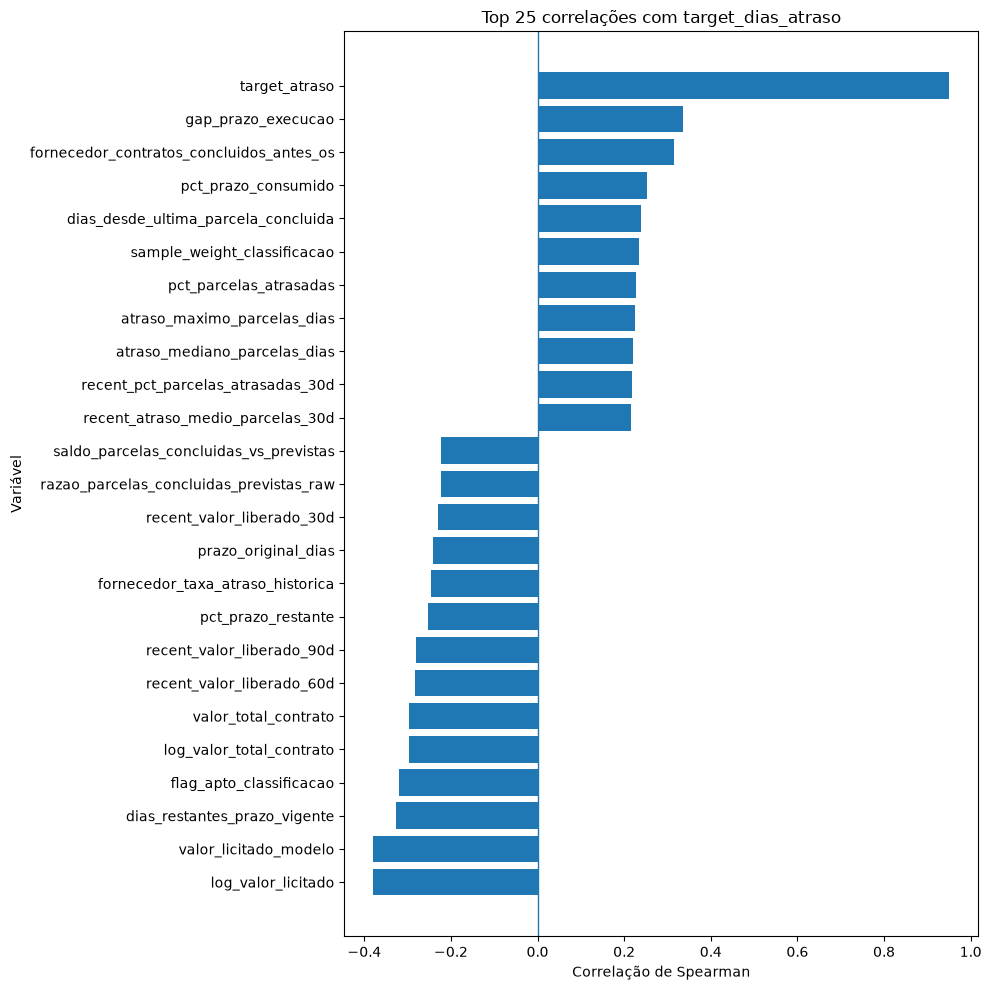

In [20]:
TOP_N = min(25, len(corr_target))

plot_df = (
    corr_target
    .head(TOP_N)
    .sort_values("spearman")
)

plt.figure(figsize=(10, 10))

plt.barh(
    plot_df["variavel"],
    plot_df["spearman"],
)

plt.axvline(0, linewidth=1)

plt.xlabel("Correlação de Spearman")
plt.ylabel("Variável")
plt.title(
    f"Top {TOP_N} correlações com {TARGET}"
)

plt.tight_layout()
plt.show()

## 4. Gráfico clássico — correlação de Pearson com o target

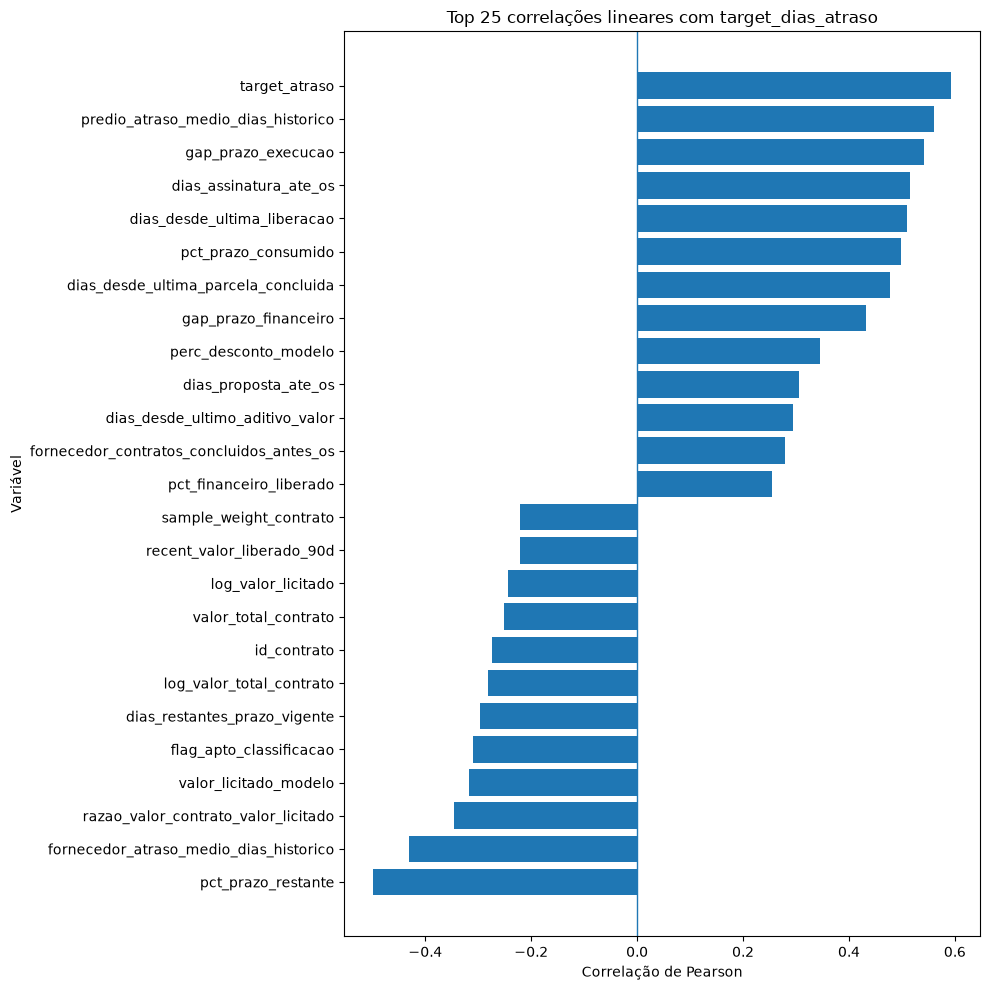

In [21]:
plot_df = (
    corr_target
    .sort_values(
        "abs_pearson",
        ascending=False,
    )
    .head(TOP_N)
    .sort_values("pearson")
)

plt.figure(figsize=(10, 10))

plt.barh(
    plot_df["variavel"],
    plot_df["pearson"],
)

plt.axvline(0, linewidth=1)

plt.xlabel("Correlação de Pearson")
plt.ylabel("Variável")
plt.title(
    f"Top {TOP_N} correlações lineares com {TARGET}"
)

plt.tight_layout()
plt.show()

## 5. Heatmap clássico das variáveis mais relacionadas ao target

Uma matriz com todas as colunas pode ficar ilegível. Por isso usamos o target mais as 15 variáveis com maior correlação absoluta de Spearman.

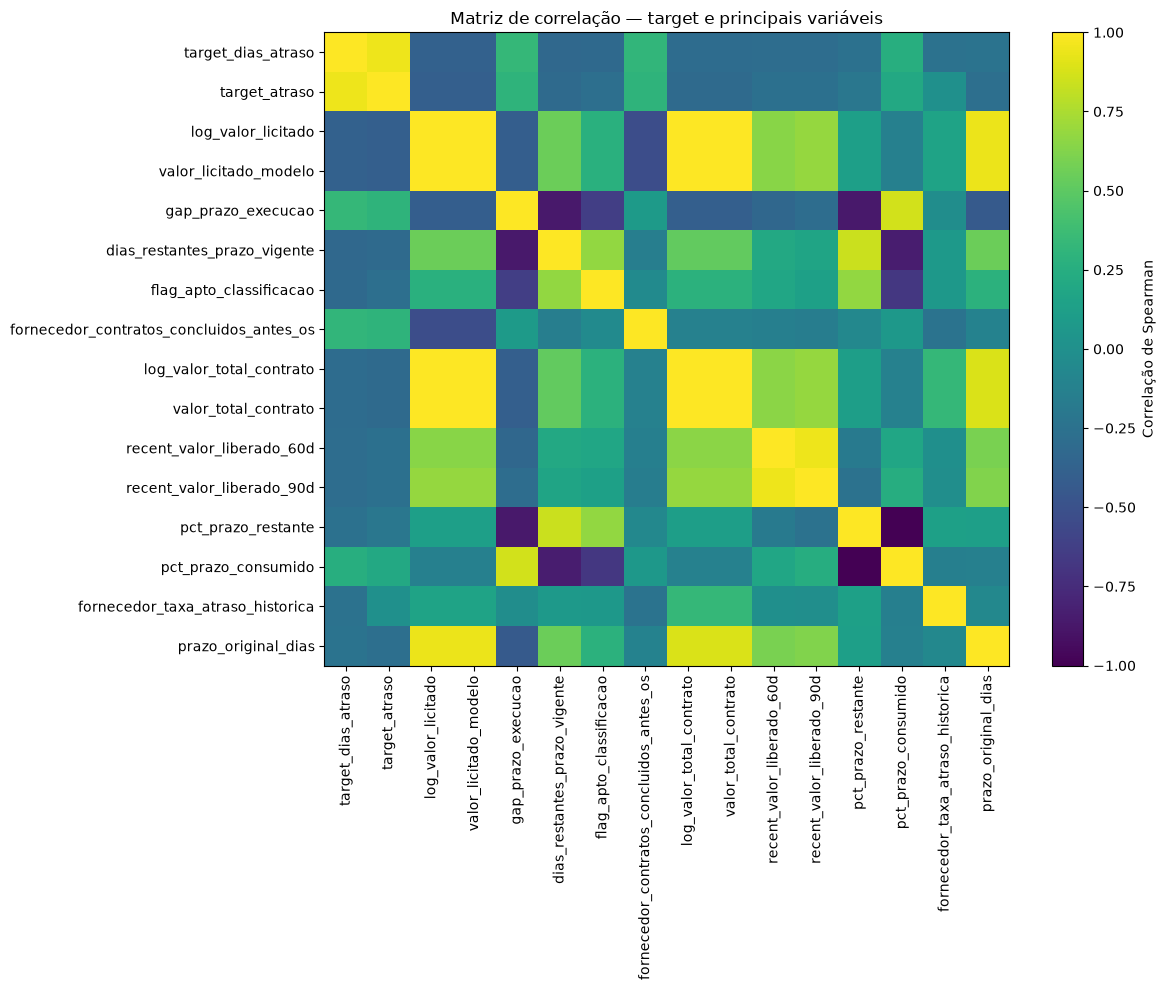

In [22]:
TOP_HEATMAP = min(15, len(corr_target))

top_features = (
    corr_target
    .head(TOP_HEATMAP)["variavel"]
    .tolist()
)

heatmap_cols = [TARGET] + top_features

corr_matrix = (
    numeric_df[heatmap_cols]
    .corr(method="spearman")
)

plt.figure(figsize=(12, 10))

img = plt.imshow(
    corr_matrix,
    aspect="auto",
    vmin=-1,
    vmax=1,
)

plt.colorbar(
    img,
    label="Correlação de Spearman",
)

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90,
)

plt.yticks(
    range(len(corr_matrix.index)),
    corr_matrix.index,
)

plt.title(
    "Matriz de correlação — target e principais variáveis"
)

plt.tight_layout()
plt.show()

## 6. Valores da matriz de correlação

A tabela numérica ajuda a verificar exatamente onde existem correlações fortes entre as próprias variáveis.

In [23]:
display(
    corr_matrix.round(3)
)

,target_dias_atraso,target_atraso,log_valor_licitado,valor_licitado_modelo,gap_prazo_execucao,dias_restantes_prazo_vigente,flag_apto_classificacao,fornecedor_contratos_concluidos_antes_os,log_valor_total_contrato,valor_total_contrato,recent_valor_liberado_60d,recent_valor_liberado_90d,pct_prazo_restante,pct_prazo_consumido,fornecedor_taxa_atraso_historica,prazo_original_dias
target_dias_atraso,1.000,0.951,-0.379,-0.379,0.335,-0.327,-0.320,0.314,-0.296,-0.296,-0.283,-0.281,-0.254,0.254,-0.247,-0.241
target_atraso,0.951,1.000,-0.397,-0.397,0.305,-0.305,-0.273,0.304,-0.310,-0.310,-0.265,-0.264,-0.206,0.206,0.004,-0.272
log_valor_licitado,-0.379,-0.397,1.000,1.000,-0.404,0.551,0.271,-0.529,1.000,1.000,0.648,0.684,0.128,-0.128,0.160,0.941
valor_licitado_modelo,-0.379,-0.397,1.000,1.000,-0.404,0.551,0.271,-0.529,1.000,1.000,0.648,0.684,0.128,-0.128,0.160,0.941
gap_prazo_execucao,0.335,0.305,-0.404,-0.404,1.000,-0.861,-0.630,0.086,-0.398,-0.398,-0.332,-0.286,-0.863,0.863,-0.023,-0.431
dias_restantes_prazo_vigente,-0.327,-0.305,0.551,0.551,-0.861,1.000,0.679,-0.144,0.516,0.516,0.208,0.166,0.839,-0.839,0.073,0.554
flag_apto_classificacao,-0.320,-0.273,0.271,0.271,-0.630,0.679,1.000,-0.047,0.289,0.289,0.182,0.140,0.673,-0.673,0.066,0.283
fornecedor_contratos_concluidos_antes_os,0.314,0.304,-0.529,-0.529,0.086,-0.144,-0.047,1.000,-0.118,-0.118,-0.134,-0.151,-0.065,0.065,-0.236,-0.113
log_valor_total_contrato,-0.296,-0.310,1.000,1.000,-0.398,0.516,0.289,-0.118,1.000,1.000,0.653,0.681,0.124,-0.124,0.329,0.890
valor_total_contrato,-0.296,-0.310,1.000,1.000,-0.398,0.516,0.289,-0.118,1.000,1.000,0.653,0.681,0.124,-0.124,0.329,0.890


## 7. Scatter plots das variáveis mais correlacionadas

Os gráficos de dispersão ajudam a enxergar se a correlação é realmente uma tendência ou se está sendo causada por poucos valores extremos.

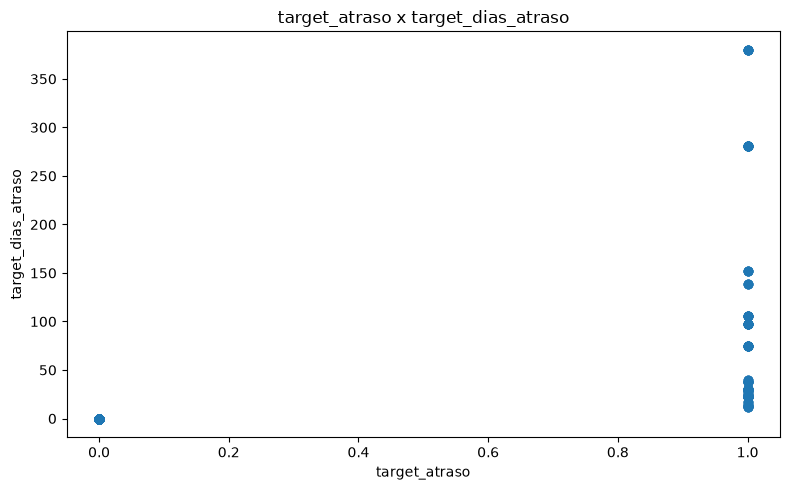

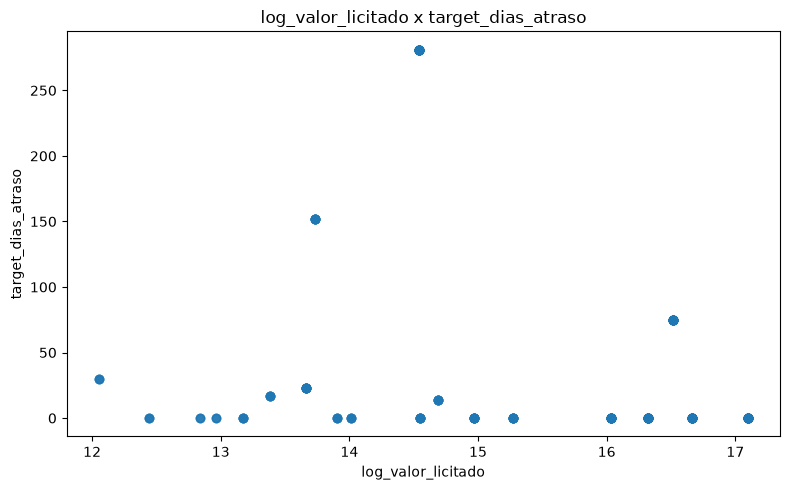

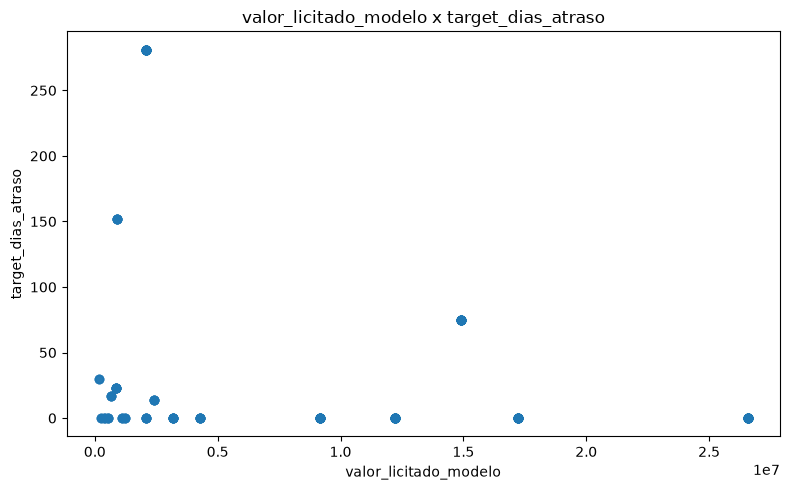

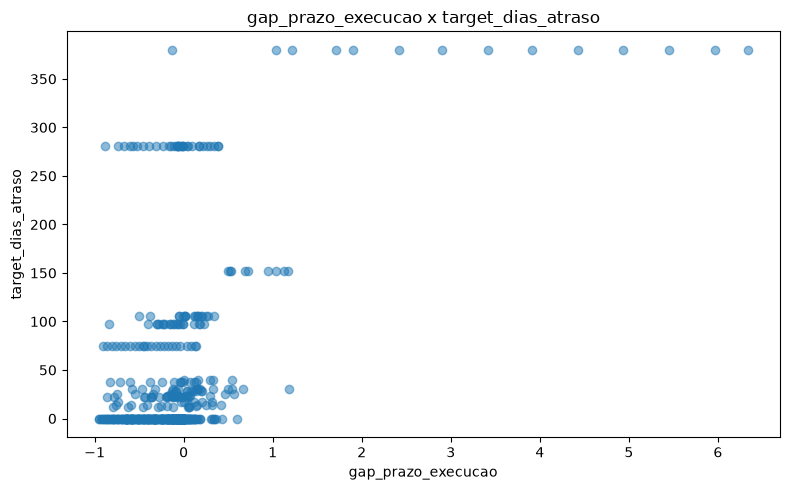

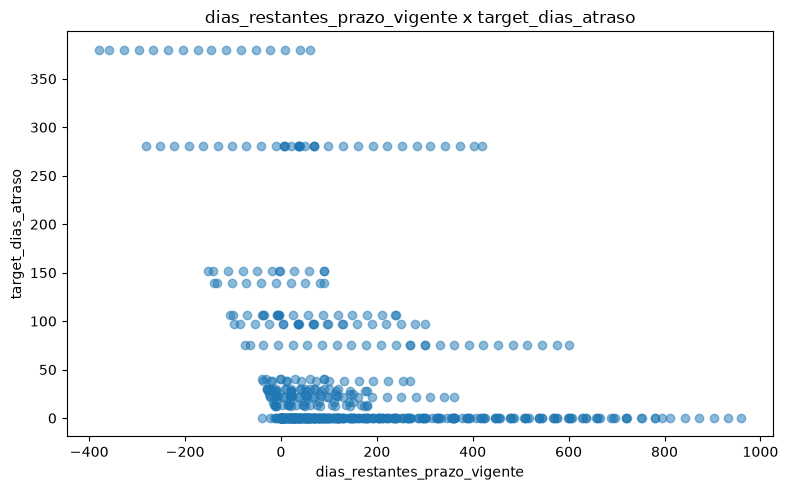

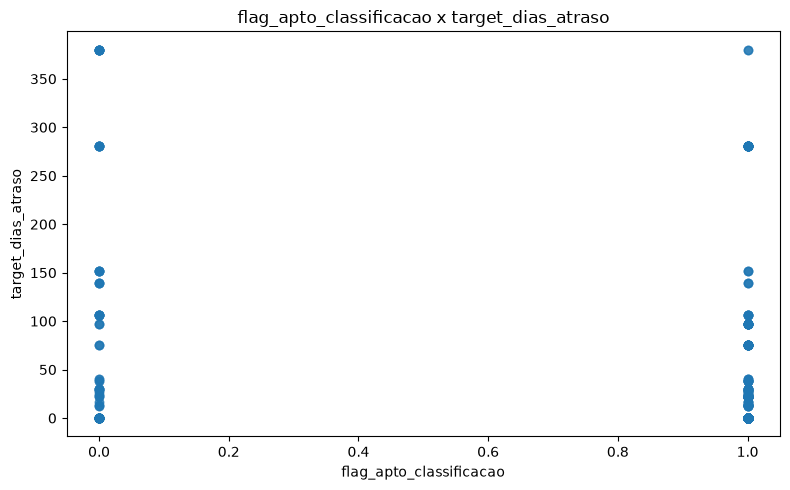

In [24]:
TOP_SCATTER = min(6, len(corr_target))

scatter_features = (
    corr_target
    .head(TOP_SCATTER)["variavel"]
    .tolist()
)

for coluna in scatter_features:

    temp = numeric_df[
        [coluna, TARGET]
    ].dropna()

    plt.figure(figsize=(8, 5))

    plt.scatter(
        temp[coluna],
        temp[TARGET],
        alpha=0.5,
    )

    plt.xlabel(coluna)
    plt.ylabel(TARGET)
    plt.title(
        f"{coluna} x {TARGET}"
    )

    plt.tight_layout()
    plt.show()

## 8. Correlações muito altas com o target

Valores absolutos muito próximos de 1 devem ser investigados com atenção.

Podem representar:
- uma relação realmente muito forte;
- uma variável derivada do próprio target;
- redundância;
- ou leakage.

In [25]:
LIMIAR_FORTE = 0.80

correlacoes_fortes = corr_target[
    (
        corr_target["abs_pearson"] >= LIMIAR_FORTE
    )
    |
    (
        corr_target["abs_spearman"] >= LIMIAR_FORTE
    )
].copy()

if len(correlacoes_fortes):
    display(
        correlacoes_fortes.round(4)
    )
else:
    print(
        f"Nenhuma variável com |correlação| >= {LIMIAR_FORTE}."
    )

,variavel,pearson,abs_pearson,spearman,abs_spearman,n,pct_nulos,valores_unicos
0,target_atraso,0.5929,0.5929,0.9508,0.9508,633,0.0,2


## 9. Correlação entre as próprias variáveis

Aqui procuramos pares de variáveis muito semelhantes entre si.

Se duas variáveis têm correlação muito alta, talvez não seja necessário manter as duas no modelo.

In [26]:
# Para não criar uma matriz enorme, usa as 30 variáveis mais relacionadas ao target.
TOP_REDUNDANCIA = min(30, len(corr_target))

cols_redundancia = (
    corr_target
    .head(TOP_REDUNDANCIA)["variavel"]
    .tolist()
)

matriz_features = (
    numeric_df[cols_redundancia]
    .corr(method="spearman")
)

pares = []

for i, col_a in enumerate(matriz_features.columns):

    for col_b in matriz_features.columns[i + 1:]:

        valor = matriz_features.loc[
            col_a,
            col_b,
        ]

        if pd.notna(valor):
            pares.append({
                "variavel_1": col_a,
                "variavel_2": col_b,
                "spearman": valor,
                "abs_spearman": abs(valor),
            })

redundancias = (
    pd.DataFrame(pares)
    .sort_values(
        "abs_spearman",
        ascending=False,
    )
)

display(
    redundancias.head(30).round(4)
)

,variavel_1,variavel_2,spearman,abs_spearman
29,log_valor_licitado,valor_licitado_modelo,1.0000,1.0000
264,pct_prazo_restante,pct_prazo_consumido,-1.0000,1.0000
182,log_valor_total_contrato,valor_total_contrato,1.0000,1.0000
34,log_valor_licitado,log_valor_total_contrato,0.9995,0.9995
35,log_valor_licitado,valor_total_contrato,0.9995,0.9995
62,valor_licitado_modelo,valor_total_contrato,0.9995,0.9995
61,valor_licitado_modelo,log_valor_total_contrato,0.9995,0.9995
325,prazo_original_dias,prazo_vigente_total_dias,0.9662,0.9662
390,razao_parcelas_concluidas_previstas_raw,saldo_parcelas_concluidas_vs_previstas,0.9631,0.9631
352,sample_weight_classificacao,prazo_vigente_total_dias,-0.9629,0.9629


## 10. Resumo simples para análise

Esta tabela final concentra as informações mais úteis para revisar as variáveis.

Não use uma regra automática de exclusão apenas pela correlação. Primeiro verifique:
- força da correlação com o target;
- quantidade de valores ausentes;
- redundância com outras variáveis;
- possibilidade de leakage;
- significado operacional da variável.

In [27]:
resumo = corr_target.copy()

resumo["correlacao_muito_baixa"] = (
    resumo["abs_spearman"] < 0.10
)

resumo["muitos_nulos"] = (
    resumo["pct_nulos"] >= 0.50
)

display(
    resumo.round(4)
)

,variavel,pearson,abs_pearson,spearman,abs_spearman,n,pct_nulos,valores_unicos,correlacao_muito_baixa,muitos_nulos
0,target_atraso,0.5929,0.5929,0.9508,0.9508,633,0.0000,2,False,False
1,log_valor_licitado,-0.2438,0.2438,-0.3794,0.3794,321,0.4929,20,False,False
2,valor_licitado_modelo,-0.3182,0.3182,-0.3794,0.3794,321,0.4929,20,False,False
3,gap_prazo_execucao,0.5416,0.5416,0.3354,0.3354,519,0.1801,467,False,False
4,dias_restantes_prazo_vigente,-0.2974,0.2974,-0.3267,0.3267,633,0.0000,338,False,False
5,flag_apto_classificacao,-0.3097,0.3097,-0.3198,0.3198,633,0.0000,2,False,False
6,fornecedor_contratos_concluidos_antes_os,0.2797,0.2797,0.3143,0.3143,633,0.0000,5,False,False
7,log_valor_total_contrato,-0.2816,0.2816,-0.2963,0.2963,633,0.0000,48,False,False
8,valor_total_contrato,-0.2523,0.2523,-0.2963,0.2963,633,0.0000,48,False,False
9,recent_valor_liberado_60d,-0.2157,0.2157,-0.2826,0.2826,633,0.0000,401,False,False


## 11. Exportação

In [28]:
OUTPUT_DIR = Path(
    "/mnt/data/06_correlacao_dados_originais_outputs"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

corr_target.to_csv(
    OUTPUT_DIR / "06_correlacao_target_variaveis_numericas.csv",
    index=False,
    encoding="utf-8-sig",
)

redundancias.to_csv(
    OUTPUT_DIR / "06_redundancias_variaveis_numericas.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Arquivos gravados em:", OUTPUT_DIR)

Arquivos gravados em: \mnt\data\06_correlacao_dados_originais_outputs


## Como interpretar

Comece pela tabela `corr_target`.

- valores positivos: quando a variável aumenta, o atraso tende a aumentar;
- valores negativos: quando a variável aumenta, o atraso tende a diminuir;
- valores próximos de zero: pouca associação linear/monotônica;
- valores muito altos: investigar relação real, redundância ou leakage.

Depois use os scatter plots e a matriz de correlação para decidir quais variáveis merecem permanecer na próxima rodada de modelagem.